# 04 Anomaly detection at San Siro

Goal: detect match-night traffic surges at San Siro using only past data and measure how many known matches each detector recovers.

Data: hourly mobile internet traffic for the San Siro zone (10 grid cells, 5636–5640 and 5736–5740), Milan, 1 Nov 2013 – 1 Jan 2014, local time (Europe/Rome). Source: Telecom Italia Big Data Challenge (Milan), via a Kaggle mirror. Traffic values are normalized and unitless.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config import TRAIN_END


zones = pd.read_csv("../data/processed/milan_zones_hourly.csv", index_col="ts", parse_dates=True)
san = zones["san_siro"]

## Event list

Ten matches played at San Siro in the study window: home games of Milan and Inter, plus Italy–Germany. Kick-off times and venues were checked against match pages; away fixtures were excluded.

Provenance: The first version of this list was built from visible traffic spikes. 4 Dec (Inter–Trapani) was added after a detector flagged it, and the list was then completed from the clubs' fixtures. Not covered: non-football events, and a Milan friendly on 16 Nov whose venue could not be verified.

In [2]:
events = pd.DataFrame(
    [
        ("2013-11-02", "20:45", "Milan vs Fiorentina", "Serie A", True),
        ("2013-11-09", "20:45", "Inter vs Livorno", "Serie A", True),
        ("2013-11-15", "20:45", "Italy vs Germany", "Friendly", True),
        ("2013-11-23", "20:45", "Milan vs Genoa", "Serie A", True),
        ("2013-12-01", "15:00", "Inter vs Sampdoria", "Serie A", True),
        ("2013-12-04", "21:00", "Inter vs Trapani", "Coppa Italia", True),
        ("2013-12-08", "20:45", "Inter vs Parma", "Serie A", True),
        ("2013-12-11", "20:45", "Milan vs Ajax", "Champions League", True),
        ("2013-12-16", "20:45", "Milan vs Roma", "Serie A", True),
        ("2013-12-22", "20:45", "Inter vs Milan", "Serie A (derby)", True),
    ],
    columns=["date", "kickoff_cet", "event", "competition", "verified"],
)

# Full timestamp for hour-level window matching
events["kickoff_datetime"] = pd.to_datetime(events["date"] + " " + events["kickoff_cet"])
events["date"] = pd.to_datetime(events["date"])

events.to_csv("../data/processed/san_siro_events.csv", index=False)
events

,date,kickoff_cet,event,competition,verified,kickoff_datetime
0,2013-11-02,20:45,Milan vs Fiorentina,Serie A,True,2013-11-02 20:45:00
1,2013-11-09,20:45,Inter vs Livorno,Serie A,True,2013-11-09 20:45:00
2,2013-11-15,20:45,Italy vs Germany,Friendly,True,2013-11-15 20:45:00
3,2013-11-23,20:45,Milan vs Genoa,Serie A,True,2013-11-23 20:45:00
4,2013-12-01,15:00,Inter vs Sampdoria,Serie A,True,2013-12-01 15:00:00
5,2013-12-04,21:00,Inter vs Trapani,Coppa Italia,True,2013-12-04 21:00:00
6,2013-12-08,20:45,Inter vs Parma,Serie A,True,2013-12-08 20:45:00
7,2013-12-11,20:45,Milan vs Ajax,Champions League,True,2013-12-11 20:45:00
8,2013-12-16,20:45,Milan vs Roma,Serie A,True,2013-12-16 20:45:00
9,2013-12-22,20:45,Inter vs Milan,Serie A (derby),True,2013-12-22 20:45:00


## Detector A: rolling robust z-score

For each hour, compare traffic with the median of the previous 168 hours, scaled by the median absolute deviation (MAD):

z_t = (x_t − median(x_{t−168..t−1})) / (1.4826 · MAD)

The current point is excluded so the score uses past data only. Median and MAD keep earlier match peaks from inflating the baseline. The first seven days are warm-up and cannot be scored.

In [3]:
def robust_z(s, window=168):
    """Rolling robust z-score against the previous `window` hours (current point excluded)."""
    past = s.shift(1)
    med = past.rolling(window).median()
    mad = past.rolling(window).apply(lambda w: np.median(np.abs(w - np.median(w))), raw=True)
    return (s - med) / (1.4826 * mad)

z = robust_z(san)
print("warm-up ends:", z.first_valid_index())

warm-up ends: 2013-11-08 00:00:00


## Evaluation protocol

Event window: 3 hours before to 4 hours after kick-off.
Detection: an event counts as detected if at least one hour inside its window exceeds the threshold K.
False alarm: any flagged hour outside every event window (strict definition).
Choices made in advance: window size and the use of the strict false-alarm definition. K = 5 was picked after the sweep below showed identical recall for K = 3–6.

In [4]:
K = 5  # chosen before the detector comparison; see sensitivity tables
pad_before, pad_after = pd.Timedelta(hours=3), pd.Timedelta(hours=4)

in_window = pd.Series(False, index=san.index)
for r in events.itertuples():
    in_window.loc[r.kickoff_datetime - pad_before : r.kickoff_datetime + pad_after] = True

def evaluate(score, k):
    rows = []
    for r in events.itertuples():
        win = score.loc[r.kickoff_datetime - pad_before : r.kickoff_datetime + pad_after]
        rows.append({"date": r.date.date(), "event": r.event,
                        "evaluable": bool(win.notna().any()),
                        "flagged_hours": int((win > k).sum()),
                        "max_score": round(win.max(), 1)})
    out = pd.DataFrame(rows)
    out["detected"] = out["flagged_hours"] > 0
    return out

### Detector A: results at K = 5

Nine of the ten events are evaluable; 2 Nov falls inside the warm-up period.

In [5]:
ev_a = evaluate(z, K)
display(ev_a)
print("recall:", round(ev_a.loc[ev_a["evaluable"], "detected"].mean(), 2))

false_alarm = (z > K) & ~in_window
print("flagged hours outside event windows:", int(false_alarm.sum()))

,date,event,evaluable,flagged_hours,max_score,detected
0,2013-11-02,Milan vs Fiorentina,False,0,NaN,False
1,2013-11-09,Inter vs Livorno,True,4,8.4,True
2,2013-11-15,Italy vs Germany,True,4,18.2,True
3,2013-11-23,Milan vs Genoa,True,4,10.2,True
4,2013-12-01,Inter vs Sampdoria,True,5,17.7,True
5,2013-12-04,Inter vs Trapani,True,1,6.1,True
6,2013-12-08,Inter vs Parma,True,3,10.1,True
7,2013-12-11,Milan vs Ajax,True,4,18.6,True
8,2013-12-16,Milan vs Roma,True,4,16.5,True
9,2013-12-22,Inter vs Milan,True,6,23.8,True


recall: 1.0
flagged hours outside event windows: 0


### Sensitivity to K (detector A, all 9 evaluable events)

Recall is identical for K = 3–6. K = 8 misses the weakest event (Inter–Trapani) and K = 10 also misses Inter–Livorno. The only flagged hour outside an event window (K = 3 and 4) is 17:00 on 22 Dec, about 45 minutes before the derby window opens.

In [6]:
rows = []
for k in (3, 4, 5, 6, 8, 10):
    ev = evaluate(z, k)
    rows.append({"K": k,
                    "recall": round(ev.loc[ev["evaluable"], "detected"].mean(), 2),
                    "false_alarm_hours": int(((z > k) & ~in_window).sum())})
display(pd.DataFrame(rows).set_index("K"))

fa3 = (z > 3) & ~in_window
print("K=3 flagged hours outside windows:", list(fa3[fa3].index))

,recall,false_alarm_hours
K,,
3,1.00,1
4,1.00,1
5,1.00,0
6,1.00,0
8,0.89,0
10,0.78,0


K=3 flagged hours outside windows: [Timestamp('2013-12-22 17:00:00')]


## Detector B: forecast residual

Baseline forecast: median of the same hour 1, 2 and 3 weeks earlier. All lags are at least 168 hours so the forecast is available a day ahead and has no trained parameters. The residual is scaled with its median and MAD over a calibration window (22 Nov – 8 Dec); no event labels are used.

Both detectors are compared on the seven events they can both score. Four of them fall inside the calibration window (robust statistics limit their influence); the last three (11, 16 and 22 Dec) are outside it.

In [7]:
lags = pd.concat([san.shift(h) for h in (168, 336, 504)], axis=1)
pred = lags.median(axis=1).where(lags.notna().all(axis=1))
resid = san - pred

calib = resid.loc["2013-11-22":TRAIN_END].dropna()
med = calib.median()
mad = (calib - med).abs().median()
z_res = (resid - med) / (1.4826 * mad)

ev_b = evaluate(z_res, K)
common = ev_a["evaluable"] & ev_b["evaluable"]
mask = z_res.notna()  # same period for false alarms

summary = pd.DataFrame({
    "robust_z": {"events": int(common.sum()),
                 "recall": round(ev_a.loc[common, "detected"].mean(), 2),
                 "false_alarm_hours": int(((z > K) & ~in_window & mask).sum())},
    "residual": {"events": int(common.sum()),
                 "recall": round(ev_b.loc[common, "detected"].mean(), 2),
                 "false_alarm_hours": int(((z_res > K) & ~in_window & mask).sum())},
})

display(summary)
display(ev_b)

,robust_z,residual
events,7.0,7.00
recall,1.0,0.86
false_alarm_hours,0.0,2.00


,date,event,evaluable,flagged_hours,max_score,detected
0,2013-11-02,Milan vs Fiorentina,False,0,NaN,False
1,2013-11-09,Inter vs Livorno,False,0,NaN,False
2,2013-11-15,Italy vs Germany,False,0,NaN,False
3,2013-11-23,Milan vs Genoa,True,0,1.4,False
4,2013-12-01,Inter vs Sampdoria,True,5,23.1,True
5,2013-12-04,Inter vs Trapani,True,3,7.1,True
6,2013-12-08,Inter vs Parma,True,3,11.7,True
7,2013-12-11,Milan vs Ajax,True,6,28.5,True
8,2013-12-16,Milan vs Roma,True,4,22.4,True
9,2013-12-22,Inter vs Milan,True,6,47.0,True


### Why the residual detector missed Milan–Genoa (23 Nov)

Two of the three reference weeks (2 and 9 Nov) contained match nights at the same hour so the median baseline already sits at match-night level and the residual is small. This is a structural limit of a seasonal-median baseline, not a threshold problem.

In [8]:
t = pd.Timestamp("2013-11-23 21:00")
for h in (168, 336, 504):
    ref = t - pd.Timedelta(hours=h)
    print(ref, round(san.loc[ref]))
print("pred:", round(pred.loc[t]), "| actual:", round(san.loc[t]))

fa_b = (z_res > K) & ~in_window & z_res.notna()
print(fa_b[fa_b].index)

2013-11-16 21:00:00 3402
2013-11-09 21:00:00 14815
2013-11-02 21:00:00 14273
pred: 14273 | actual: 12449
DatetimeIndex(['2013-12-22 16:00:00', '2013-12-22 17:00:00'],
              dtype='datetime64[us]', name='ts', freq=None)


## Comparison across thresholds

At K = 5 the robust z-score detects all 7 common events with no false alarms; the residual detector detects 6 of 7 with 2 false-alarm hours (both on 22 Dec, shortly before the derby window).

At K = 3 the residual detector produces 30 false-alarm hours, against 1 for the robust z-score.

The two scores have different scales (the residual MAD is smaller, so its scores are larger), so equal K values are not equivalent. Compare operating points rather than thresholds. With 7 events, one event changes recall by 0.14, so the two detectors cannot be ranked reliably.

In [9]:
def sweep(score, ks=(3, 4, 5, 6, 8, 10, 15, 20)):
    rows = []
    for k in ks:
        ev = evaluate(score, k)
        rows.append({
            "K": k,
            "recall": round(ev.loc[common, "detected"].mean(), 2),
            "false_alarm_hours": int(((score > k) & ~in_window & mask).sum()),
        })
    return pd.DataFrame(rows).set_index("K")

sweep_table = pd.concat({"robust_z": sweep(z), "residual": sweep(z_res)}, axis=1)
display(sweep_table)
sweep_table.to_csv("../outputs/metrics/anomaly_detector_sweep.csv")

events_cmp = ev_a.merge(ev_b, on=["date", "event"], suffixes=("_robust_z", "_residual"))
events_cmp.to_csv("../outputs/metrics/anomaly_events_comparison.csv", index=False)

robust_z                   residual                  
     recall false_alarm_hours   recall false_alarm_hours
K                                                       
3      1.00                 1     0.86                30
4      1.00                 1     0.86                 3
5      1.00                 0     0.86                 2
6      1.00                 0     0.86                 1
8      0.86                 0     0.71                 1
10     0.86                 0     0.71                 0
15     0.57                 0     0.57                 0
20     0.14                 0     0.57                 0

### Alerts against known match windows

Red points are hours flagged by detector A (K = 5); shaded bands are the event windows. No flagged hour falls outside a window.

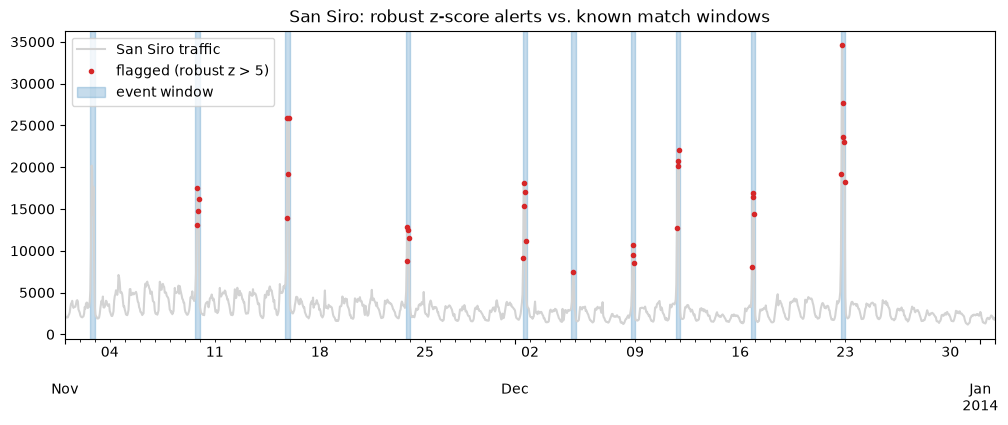

In [10]:
flag = z > K
fig, ax = plt.subplots(figsize=(12, 4))
san.plot(ax=ax, color="lightgray", label="San Siro traffic")
san[flag].plot(ax=ax, style="o", ms=3, color="tab:red", label="flagged (robust z > 5)")
for i, r in enumerate(events.itertuples()):
    ax.axvspan(r.kickoff_datetime - pad_before, r.kickoff_datetime + pad_after,
                   color="tab:blue", alpha=0.25, label="event window" if i == 0 else None)
ax.legend()
ax.set_xlabel("")
ax.set_title("San Siro: robust z-score alerts vs. known match windows")
fig.savefig("../outputs/figures/san_siro_anomalies_detected.png", dpi=150, bbox_inches="tight")

## Limitations

- Nine evaluable events, one location, two months: results show how the detectors behave on this data, not how they generalize.
- Robust z-score works well here because San Siro's baseline is flat; it was not tested on zones with strong daily cycles such as the city centre.
- Recall is measured against football matches only; concerts or other events are not in the list.
- K = 5 was chosen after inspecting the sweep; the window definition was fixed beforehand.
- The residual detector's baseline can be contaminated when reference weeks contain events (see Milan–Genoa).